# Step 3: Exploratory Data Analysis and Visualization

- **Goal:** Explore the cleaned dataset with summary statistics and charts to find patterns in sales, profit, discounts, delivery and returns.

- **Input:** `data/processed/ecommerce_orders_clean.csv` (created in notebook 02)
- **Output:** charts saved in `reports/figures/`

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", 50)

**Note:** Seaborn theme and default figure size are set once so all charts look consistent.

### Load the cleaned dataset
`parse_dates` is needed because a CSV file does not store the datetime type.

In [11]:
df = pd.read_csv("../data/processed/ecommerce_orders_clean.csv", parse_dates=["Order_Date"])
print(df.shape)
df.head()

(5000, 31)


,Order_ID,Order_Date,Customer_ID,Customer_Name,Gender,Age,Country,Region,City,Customer_Segment,Product_ID,Product_Name,Category,Sub_Category,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Order_Status,Shipping_Method,Delivery_Days,Customer_Rating,Returned,Marketing_Channel,Device_Type,Year,Month,Total_Cost
0,ORD703665,2024-05-27,C10815,Unknown,Female,38.0,Austria,Styria,Graz,Consumer,P1011,Air Fryer,Home & Kitchen,Kitchen,2,131.55,0.350,171.01,80.43,10.15,Credit Card,Cancelled,Standard,NaN,NaN,0,Organic Search,Desktop,2024,5,160.86
1,ORD700607,2024-07-31,C11410,Anna Wagner,Male,42.0,France,Auvergne-Rhône-Alpes,Lyon,Unknown,P1018,Yoga Mat,Sports,Fitness,3,35.61,0.242,81.00,15.50,34.51,Credit Card,Returned,Standard,NaN,3.6,1,Direct,Mobile,2024,7,46.50
2,ORD703810,2023-05-04,C11152,Anna Bauer,Female,37.0,Germany,North Rhine-Westphalia,Dortmund,Consumer,P1011,Air Fryer,Home & Kitchen,Kitchen,1,137.35,0.151,116.64,82.21,34.43,PayPal,Delivered,Express,2.0,4.9,0,Direct,Desktop,2023,5,82.21
3,ORD703060,2025-08-03,C10177,Noah Bauer,Female,43.0,Netherlands,Utrecht,Utrecht,Consumer,P1003,USB-C Dock,Electronics,Computer Accessories,2,72.19,0.155,122.02,41.94,38.15,Bank Transfer,Delivered,Standard,9.0,3.9,0,Paid Search,Mobile,2025,8,83.88
4,ORD704419,2025-06-16,C11289,Laura Wagner,Unknown,41.0,Netherlands,North Holland,Amsterdam,Unknown,P1003,USB-C Dock,Electronics,Computer Accessories,2,75.67,0.222,117.78,41.19,35.39,Debit Card,Delivered,Standard,3.0,3.5,0,Organic Search,Desktop,2025,6,82.38


In [12]:
df["Age"] = df["Age"].astype("Int64")
df["Delivery_Days"] = df["Delivery_Days"].astype("Int64")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 31 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Order_ID           5000 non-null   str           
 1   Order_Date         5000 non-null   datetime64[us]
 2   Customer_ID        5000 non-null   str           
 3   Customer_Name      5000 non-null   str           
 4   Gender             5000 non-null   str           
 5   Age                4829 non-null   Int64         
 6   Country            5000 non-null   str           
 7   Region             5000 non-null   str           
 8   City               5000 non-null   str           
 9   Customer_Segment   5000 non-null   str           
 10  Product_ID         5000 non-null   str           
 11  Product_Name       5000 non-null   str           
 12  Category           5000 non-null   str           
 13  Sub_Category       5000 non-null   str           
 14  Quantity           

**Result:** The dataset has 5,000 rows and 31 columns. `Order_Date` is `datetime64`. Missing values remain only in `Age`, `Delivery_Days` and `Customer_Rating` (kept on purpose in Step 2).

### Summary statistics
Overview of the numeric columns: range, average and spread.

In [13]:
num_cols = ["Age", "Quantity", "Unit_Price", "Discount", "Sales", "Cost", "Profit", "Delivery_Days", "Customer_Rating"]
df[num_cols].describe().round(2)

,Age,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Delivery_Days,Customer_Rating
count,4829.0,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,4551.0,4478.00
mean,37.23,1.90,117.35,0.18,179.54,72.50,42.94,4.35,3.97
std,10.64,1.06,99.97,0.10,205.36,71.09,50.21,2.88,0.69
min,18.0,1.00,16.66,0.00,11.09,6.52,-161.17,0.0,1.40
25%,30.0,1.00,38.84,0.10,54.12,20.03,13.98,2.0,3.50
50%,37.0,2.00,83.02,0.17,109.24,46.59,28.38,4.0,4.00
75%,44.0,2.00,145.17,0.27,225.98,87.96,54.56,7.0,4.50
max,75.0,5.00,435.88,0.35,1942.80,312.67,575.19,10.0,5.00


- **Result:** Quantity ranges from 1 to 5 (average 1.90). Discount ranges from 0.00 to 0.35 (average 0.18, about 18%). Profit has a minimum of -161.17, so some orders lose money; the average profit per order is 42.94 and the maximum is 575.19. Average sales per order is 179.54, with a maximum of 1,942.80. Customer ratings range from 1.40 to 5.00 with an average of 3.97. Delivery takes 4.35 days on average (0 to 10 days). The `count` row confirms the missing values kept in Step 2: Age 4,829, Delivery_Days 4,551, Customer_Rating 4,478 out of 5,000.
- Average sales (179.54) is much higher than the median (109.24), so a few large orders pull the average up. The median is a better measure of a typical order.

### Order status and the rule for revenue
Cancelled orders did not generate revenue, so they are excluded from sales and profit totals. Returned orders are kept in the data and analysed separately in Step 4.

In [14]:
print(df["Order_Status"].value_counts())
print()
print(df["Order_Status"].value_counts(normalize=True).round(3))

# Orders that count as revenue
sales_df = df[df["Order_Status"] != "Cancelled"].copy()
print("\nAll orders:", len(df), " Revenue orders:", len(sales_df))

Order_Status
Delivered    4400
Returned      344
Cancelled     256
Name: count, dtype: int64

Order_Status
Delivered    0.880
Returned     0.069
Cancelled    0.051
Name: proportion, dtype: float64

All orders: 5000  Revenue orders: 4744


**Result:** 256 of 5,000 orders were cancelled and are excluded from revenue. The remaining 4,744 orders are stored in `sales_df` and used for sales and profit charts.

### Monthly sales and profit
Total sales and profit per month for revenue orders (cancelled orders excluded).

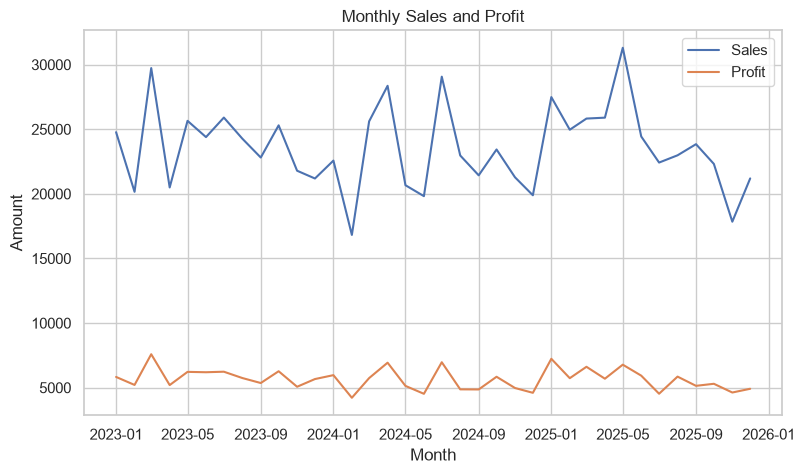

In [15]:
monthly = sales_df.resample("MS", on="Order_Date")[["Sales", "Profit"]].sum()

fig, ax = plt.subplots()
ax.plot(monthly.index, monthly["Sales"], label="Sales")
ax.plot(monthly.index, monthly["Profit"], label="Profit")
ax.set_title("Monthly Sales and Profit")
ax.set_xlabel("Month")
ax.set_ylabel("Amount")
ax.legend()
plt.savefig("../reports/figures/01_monthly_sales_profit.png", dpi=150, bbox_inches="tight")
plt.show()

Check: highest and lowest months and the top 4 profit months.

In [16]:
print("Highest sales:", monthly["Sales"].idxmax().strftime("%Y-%m"), round(monthly["Sales"].max()))
print("Lowest sales: ", monthly["Sales"].idxmin().strftime("%Y-%m"), round(monthly["Sales"].min()))
print(monthly.sort_values("Profit", ascending=False).head(4).round(0))

Highest sales: 2025-05 31306
Lowest sales:  2024-02 16821
              Sales  Profit
Order_Date                 
2023-03-01  29734.0  7589.0
2025-01-01  27488.0  7235.0
2024-07-01  29071.0  6969.0
2024-04-01  28363.0  6934.0


**Observation:** Monthly sales fluctuate between about 17,000 and 31,000 from 2023 to 2025 with no clear upward or downward trend. The highest month is May 2025 (31,306) and the lowest is February 2024 (16,821). Sales also dip at the end of 2025. Profit stays in a narrow band of about 4,500 to 7,500 and moves in the same direction as sales: its peaks (March 2023, July 2024, January 2025, May 2025) match the sales peaks, but the swings are much smaller. No strong seasonal pattern is visible; the month-to-month changes look irregular, which is expected in synthetic data.